# Tutorial 8: Measuring the impact of a retracted paper

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/melhzy/pubmed-stream/blob/main/tutorials/08_retraction_impact.ipynb) Run it in your browser with nothing to install, or on your own computer: [how to run the tutorials](guides/setup.md).

In 2006, *Nature* published **"A specific amyloid-β protein assembly in the brain impairs memory"** (Lesné and colleagues, [PMID 16541076](https://pubmed.ncbi.nlm.nih.gov/16541076/)). It reported **Aβ\*56**, an assembly of amyloid-β that impaired memory in mice, and it became one of the most cited papers in Alzheimer's disease research. In July 2022 an investigation in *Science* raised concerns about manipulated images in it, and *Nature* added an editor's note. In June 2024 the paper was **retracted**, with all authors except the first agreeing ([retraction notice, PMID 38914864](https://pubmed.ncbi.nlm.nih.gov/38914864/)).

A retraction removes a paper from the record, but not the papers built on it. This tutorial measures how far the paper reached, and how the papers citing it use it.

## In brief

From the saved run, on 19 October 2026:

- **It reached one in seven Alzheimer's papers.** 1,240 papers in PubMed cite it, and 44,921 more cite one of those: together, 15,039 of the 107,302 Alzheimer's disease papers in PubMed since 2006.
- **Most papers cite it for a general idea.** Of the 879 citing papers whose citing sentence could be read, from the full text or from Semantic Scholar, 687 cite it for a general statement about amyloid-β oligomers and memory; 180 name Aβ\*56.
- **Few say it is in doubt.** 74 papers cite it from 2022 on; only 11 of them mention the retraction or the doubts where they cite it.
- **It is still cited after the retraction.** 24 papers cite it from 2024 to 2026. Of the 19 that could be read, 7 say it is retracted or in doubt, 11 cite it as evidence for a general statement, and 1, co-authored by its senior author, reports Aβ\*56 as a finding. Section 5 lists them all.
- **The work built on it is still growing.** Citations of the paper peaked in 2012, but papers citing its citers still grow, to about 4,000 a year.
- **Retractions cluster.** 6 papers citing it have been retracted too, 4 of them with the same first author.

The sections below show how each number is measured, with a chart for each, and build a knowledge graph to explore in Obsidian. The same notebook measures any other paper if you change the settings. Words such as MeSH, PMC or stub are explained in the [glossary](guides/glossary.md).

**Time:** about 15 minutes, mostly to download the full text of the citing papers (about 100 MB). A free NCBI API key makes it about three times faster.

## Your settings

This is the only cell you need to edit. To study another paper, change the PubMed ID, its DOI, a few words of its title, and the words that name its specific finding. For a paper that was not retracted, leave the two dates empty.

In [1]:
SEED = "16541076"                 # PubMed ID of the paper: A specific amyloid-beta protein assembly in the brain impairs memory
SEED_DOI = "10.1038/nature04533"  # its DOI, to find it in reference lists
TITLE_WORDS = "specific amyloid"  # a few words of its title, for references without a DOI
FINDING = "Aβ*56"                 # a short name for its specific finding, for the charts
FINDING_WORDS = ["Aβ*56", "Abeta*56", "A beta*56", "A *56", "Aβ56", "Aβ-56", "Abeta56", "56-kDa", "56 kDa"]   # how authors write it
DOUBTS_PUBLIC = "2022-07"         # year and month doubts about the paper became public, or ""
RETRACTED = "2024-06"             # year and month it was retracted, or ""
FIELD = "Alzheimer Disease"       # the MeSH heading of its field, to put its reach in proportion
SECOND_HOP_SEEDS = 10             # citing papers whose own neighborhoods join the knowledge graph
NCBI_API_KEY = ""   # optional: paste your free NCBI key between the quotes to run about three times faster

In [2]:
# Setup: run this cell as it is. In Google Colab it first fetches the tutorial files.
import os
import re
import subprocess
import sys

if "google.colab" in sys.modules:
    if not os.path.isdir("/content/pubmed-stream"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/melhzy/pubmed-stream.git", "/content/pubmed-stream"], check=True)
    sys.path.insert(0, "/content/pubmed-stream/tutorials")

import pandas as pd

import tutorial_utils as tu

tu.setup("retraction_impact", api_key=NCBI_API_KEY)
tu.style()
pd.set_option("display.max_colwidth", 200)

from pubmed_stream import impact as ci
import impact_charts as charts
from pubmed_stream import create_kg, download_neighborhood, get_neighborhood

finding = re.compile("|".join(re.escape(w) for w in FINDING_WORDS), re.I)
KINDS = [ci.KINDS[0], f"Names {FINDING}", ci.KINDS[2], ci.KINDS[3]]
COLOURS = dict(zip(KINDS, [tu.ORANGE, tu.BLUE, tu.AQUA, tu.GREY]))
EVENTS = [(int(d[:4]) - 0.5 + (int(d[5:7]) - 1) / 12, f"{pd.Timestamp(d + '-01'):%b %Y}\n{label}")
          for d, label in [(DOUBTS_PUBLIC, "doubts published"), (RETRACTED, "retracted")] if d]

## 1. The paper and its notices

`get_neighborhood` fetches the paper with **every** paper PubMed links to it: here up to 5,000 citing papers instead of the usual 100. PubMed also links the notices published about a paper: its retraction, corrections and comments.

In [3]:
hood = get_neighborhood(SEED, max_per_relation=5000)
seed = hood.seed
first_year = int(seed.year)
print(f"{seed.title}\n{', '.join(seed.authors)}\n{seed.journal}, {seed.year}. Retracted: {seed.is_retracted}")
pd.DataFrame(ci.corrections(SEED))

A specific amyloid-beta protein assembly in the brain impairs memory.
Lesné Sylvain, Koh Ming Teng, Kotilinek Linda, Kayed Rakez, Glabe Charles G, Yang Austin, Gallagher Michela, Ashe Karen H
Nature, 2006. Retracted: True


,type,pmid,source
0,Comment In,16541054,Nature. 2006 Mar 16;440(7082):284-5. doi: 10.1038/440284a.
1,Retraction In,38914864,Nature. 2024 Jul;631(8019):240. doi: 10.1038/s41586-024-07691-8.


## 2. How far did it reach?

The **neighbors** are the papers that cite it. The **neighbors' neighbors** are the papers that cite one of those: they may never cite the retracted paper themselves, but they build on work that does. PubMed answers both questions with its citation links, a hundred papers per request, so this cell takes two or three minutes. It also counts the papers of the paper's field, to put the reach in proportion.

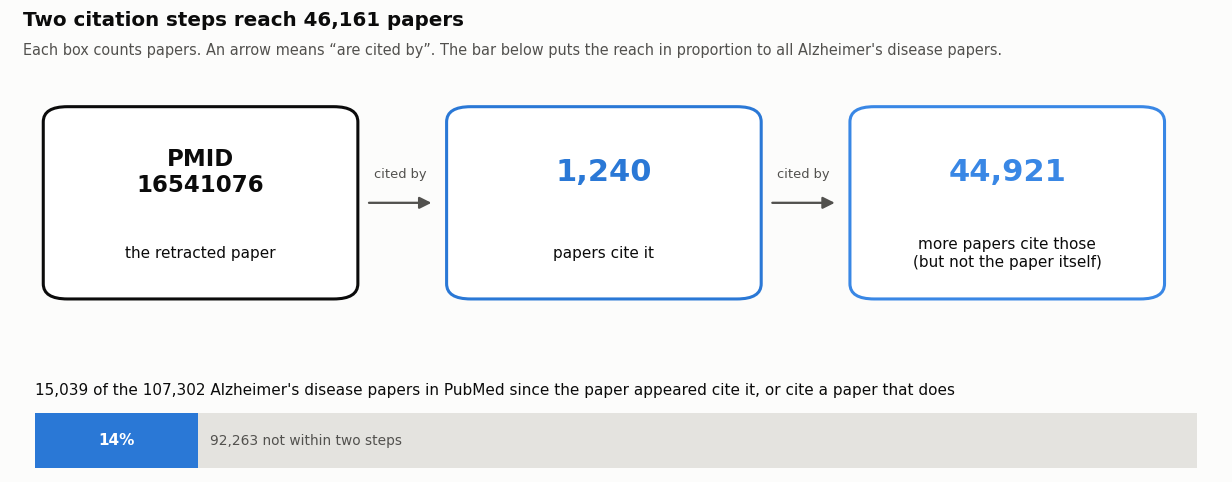

In [4]:
hop1 = {a.pmid for a in hood.cited_by}
citers = ci.citers_of(sorted(hop1))
hop2 = set().union(*citers.values()) - hop1 - {SEED}
field_total = ci.pubmed_count(f'"{FIELD}"[mh] AND {first_year}:3000[dp]')
field_near = ci.count_matching(hop1 | hop2, {"field": f'"{FIELD}"[mh]'})["field"]

field_label = FIELD.replace(" Disease", "'s disease")   # "Alzheimer Disease" reads "Alzheimer's disease"
charts.reach(f"PMID\n{SEED}", len(hop1), len(hop2), field_total, field_near, field_label)

The second step is an upper bound on influence, not a measure of harm: a paper that cites a broad review of amyloid-β, which happens to cite the retracted paper, counts too. Section 4 narrows it down by reading how each paper cites it.

## 3. When was it cited?

PubMed's citation links come from articles deposited in PubMed Central, so they count fewer citations than Google Scholar or Web of Science, and the current year is incomplete; its bars are paler.

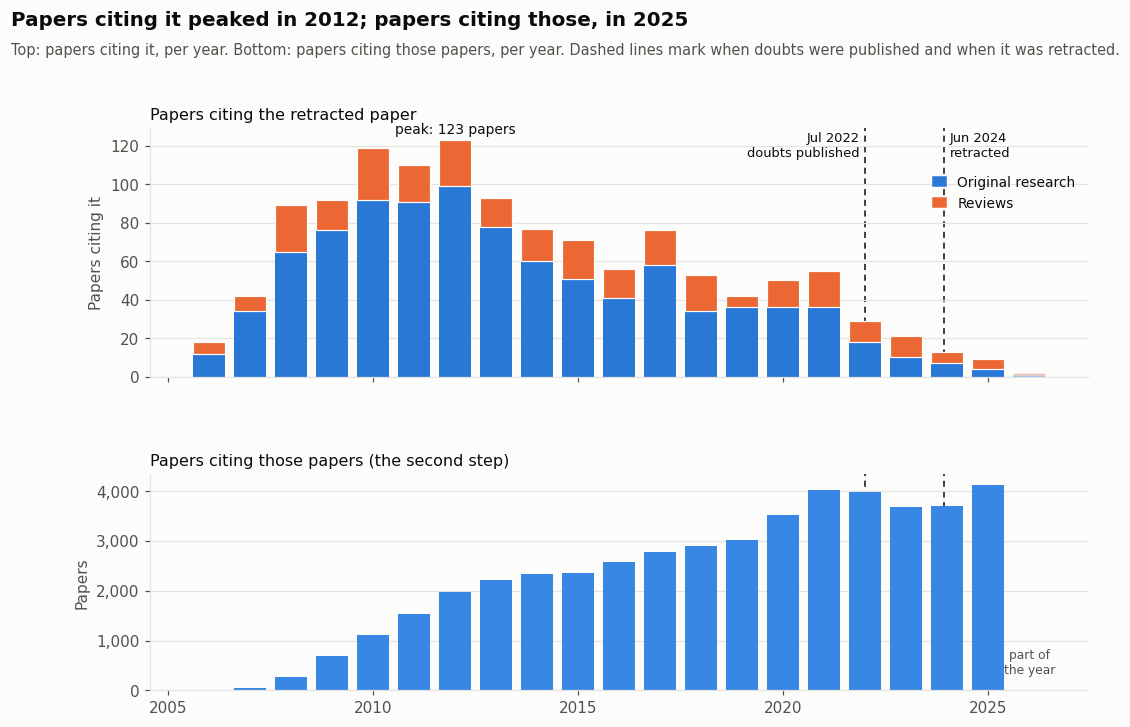

In [5]:
def person(name):   # last name and first initial: PubMed writes "Lesné Sylvain" and "Lesné Sylvain E"
    parts = name.split()
    return (parts[0], parts[1][:1]) if len(parts) > 1 else (name, "")

seed_people = {person(n) for n in seed.authors}
cited_by = pd.DataFrame([{"pmid": a.pmid, "year": int(a.year), "review": a.is_review, "retracted": a.is_retracted,
                          "pmcid": a.pmcid, "title": a.title, "journal": a.journal, "authors": a.authors,
                          "shared_authors": ", ".join(n for n in a.authors if person(n) in seed_people)}
                         for a in hood.cited_by if a.year and a.year.isdigit()])
last_year = int(cited_by["year"].max())
years = list(range(first_year, last_year + 1))
per_year = (cited_by.groupby(["year", "review"]).size().unstack(fill_value=0)
            .reindex(index=years, columns=[False, True], fill_value=0))
hop2_years = ci.count_by_year(hop2, first_year, last_year)

charts.timeline(years, list(per_year[False]), list(per_year[True]), hop2_years, EVENTS,
                partial=pd.Timestamp.today().year)

## 4. How was it cited?

A citation count says nothing about **why** a paper was cited. Was it the evidence for a key step in the argument, one of many references for a general statement, or an example of a problem? The full text answers that.

The next cell downloads the full text of every citing paper in PubMed Central, as XML. In XML each citation is marked, so `ci.citation_contexts` can find the exact sentence that cites the paper, even inside a range such as [10–14]. Many publishers withhold the full text from PubMed Central; for those papers, the sentences come from [Semantic Scholar](https://www.semanticscholar.org), which extracts citing sentences from papers it can read. `ci.classify` then sorts each citing paper by its sentences, in this order:

| Kind | The sentence citing the paper... | Colour |
|---|---|---|
| **Discusses the retraction or doubts** | mentions the retraction, manipulated data or images, fabrication, an editor's note, concerns about the paper, or a failure to reproduce it | orange |
| **Names Aβ\*56** | names the specific finding, with one of `FINDING_WORDS` | blue |
| **Cites it in general** | supports a general statement, such as "soluble oligomers impair memory" | aqua |
| **No full text, or citation not found** | could not be read: neither PubMed Central nor Semantic Scholar has the sentence, or it could not be found, for instance because it is in a table | grey |

The classification uses keywords, so it makes mistakes: read the examples below before you trust the counts.

In [6]:
with tu.quiet():
    stats = download_neighborhood(hood, output_dir="fulltext", fmt="xml", include_text=False)
contexts = ci.citation_contexts(stats.output_dir, SEED, SEED_DOI, TITLE_WORDS, finding=finding)
by_pmid = {c["pmid"]: c for c in contexts.values() if c["pmid"] and c["sentences"]}
s2 = ci.semantic_scholar_contexts(SEED)   # citing sentences for the papers PubMed Central cannot give

def sentences_of(pmid):
    if pmid in by_pmid:
        return by_pmid[pmid]["sentences"], "full text"
    return (s2[pmid], "Semantic Scholar") if pmid in s2 else ([], "")

def label(kind):
    return f"Names {FINDING}" if kind == ci.KINDS[1] else kind

read_from = cited_by["pmid"].map(sentences_of)
cited_by["source"] = read_from.str[1]
cited_by["sentence"] = read_from.str[0].map(" … ".join)
raw_kinds = read_from.str[0].map(lambda s: ci.classify(s, finding))
cited_by["kind"] = raw_kinds.map(label)
cited_by["second_look"] = [ci.worth_a_look(s, k) for s, k in zip(read_from.str[0], raw_kinds)]
cited_by["mentions"] = cited_by["pmid"].map(lambda p: by_pmid.get(p, {}).get("mentions"))
print(f"Full text downloaded: {stats.successful + stats.skipped} of {stats.requested} articles in PubMed Central; "
      f"{stats.unavailable} withheld by their publishers")
print("Citing sentences read from:", ", ".join(f"{src or 'nowhere'} {n}" for src, n in cited_by["source"].value_counts().items()))
cited_by["kind"].value_counts().reindex(KINDS, fill_value=0).to_frame("citing papers")

Full text downloaded: 832 of 1207 articles in PubMed Central; 375 withheld by their publishers
Citing sentences read from: full text 756, nowhere 361, Semantic Scholar 123


,citing papers
kind,
Discusses the retraction or doubts,12
Names Aβ*56,180
Cites it in general,687
"No full text, or citation not found",361


The chart counts only the papers that could be read, so that the grey ones do not hide the others; the right edge says how many each period has.

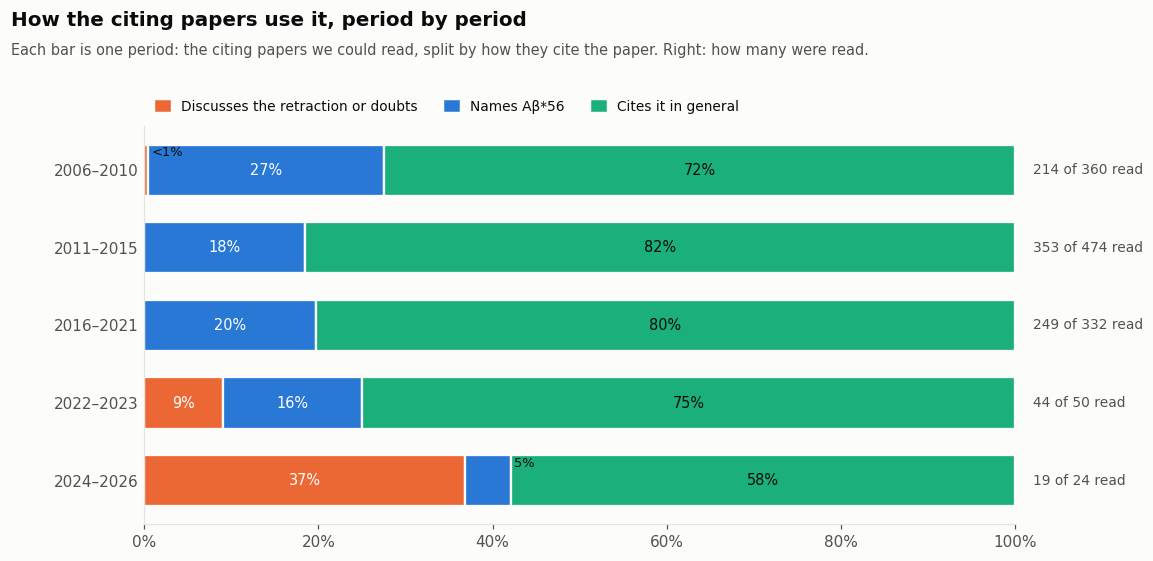

In [7]:
edges = [first_year, 2011, 2016] + [int(d[:4]) for d in (DOUBTS_PUBLIC, RETRACTED) if d] + [last_year + 1]
edges = sorted(set(e for e in edges if first_year <= e <= last_year + 1))
periods = [f"{a}–{b - 1}" if b - 1 > a else str(a) for a, b in zip(edges, edges[1:])]
cited_by["period"] = pd.cut(cited_by["year"], edges, right=False, labels=periods)
read = cited_by[cited_by["kind"] != KINDS[3]]
counts = {p: read[read["period"] == p]["kind"].value_counts().to_dict() for p in periods}
unread = cited_by[cited_by["kind"] == KINDS[3]]["period"].value_counts().to_dict()

charts.kinds_by_period(periods, counts, unread, KINDS[:3], COLOURS, "How the citing papers use it, period by period")

Read a few sentences of each kind. They show what the paper was used for, and whether the classification is right. **⟦CITE⟧** marks the place where the sentence cites the retracted paper; the other numbers are its other references.

In [8]:
examples = (read.sort_values("year", ascending=False).groupby("kind").head(3).sort_values(["kind", "year"]))
examples[["kind", "year", "pmid", "sentence"]].assign(sentence=examples["sentence"].map(lambda s: tu.short(s, 300)))

,kind,year,pmid,sentence
6,Cites it in general,2025,40076721,"Their ability to inhibit long-term potentiation (LTP) and many other critical neuronal activities is responsible for the classic model of synaptic plasticity and memory loss in vivo, for example, ..."
2,Cites it in general,2025,41624198,"The amyloid-beta (Aβ) hypothesis proposes that soluble Aβ oligomers (SO-Aβ) are major drivers of synaptic dysfunction and neuronal injury (⟦CITE⟧, 3)."
11,Cites it in general,2025,39422790,"However, it is unclear whether AD pathogenesis is driven by non-fibrillar Aβ multimers or amyloid plaques [97, ⟦CITE⟧]."
3,Discusses the retraction or doubts,2025,41227148,"Chistian Piller, journalist at e-Science, documented several examples of this scientific pressure: the retraction of an influential article published in 2006 in Nature [⟦CITE⟧,96] about the role o..."
7,Discusses the retraction or doubts,2025,39996369,"Candidates have included dimers,51 dodecamers52 (note: the initial 2006 study identifying dodecamers⟦CITE⟧ was recently retracted due to data manipulation), and even a heterogeneous “oligomeric so..."
4,Discusses the retraction or doubts,2025,40413393,"In an extreme example, post-publication peer review and “sleuthing” successfully identified serious errors in Alzheimer’s disease research [⟦CITE⟧, 6], but more than a decade after the original pu..."
48,Names Aβ*56,2022,36359817,"For example, Aβ*56, a distinct species of Aβ oligomers with a molecular weight of 56 kDa, was proposed as a promising candidate to explain the genesis of AD, since the injection of such aggregates..."
33,Names Aβ*56,2023,37216514,Concentrations of Aβ trimers are elevated in cognitively normal adults who are at risk for Alzheimer’s disease (⟦CITE⟧). … Aβ trimers appear to be the building blocks of the putative dodecamer of ...
18,Names Aβ*56,2024,38433923,"Aβ*56 was the first brain-derived amyloid-β (Aβ) oligomer shown to impair memory in mice and rats.⟦CITE⟧ … In keeping with PrP*, Aβ*56 appears to be neurotoxic and associates closely with impaired..."


In [9]:
in_full = read[read["source"] == "full text"]
never = (in_full["mentions"] == 0).sum()
print(f"{never} of the {len(in_full)} citing papers read in full text ({never / len(in_full):.0%}) never mention "
      f"{FINDING} anywhere in their text: they cite the paper for a broader claim.")

576 of the 756 citing papers read in full text (76%) never mention Aβ*56 anywhere in their text: they cite the paper for a broader claim.


### Worth a second look

Keywords catch clear statements such as "was retracted" or "falsified images", but not softer ones. These are the citations sorted as general, or as naming the finding, whose sentence uses a word such as *debated*, *uncertain*, *controversial* or *not detected*. Most are about amyloid-β in general, not about this paper; read them to decide.

In [10]:
second_look = cited_by[cited_by["second_look"]].sort_values("year", ascending=False)
print(f"{len(second_look)} citations worth a second look")
charts.paper_table(second_look.to_dict("records"), COLOURS)

28 citations worth a second look


Year,Paper,How it cites it,The sentence that cites it
2025,Proteostasis and Its Role in Disease Development.Cell biochemistry and biophysics · PMID 39422790,Cites it in general,"However, it is unclear whether AD pathogenesis is driven by non-fibrillar Aβ multimers or amyloid plaques [97, [this paper]]."
2024,Real-Time Tracking of Vesicles in Living Cells Reveals That Tau-Hyperphosphorylation Suppresses Unidirectional Transport by Motor Proteins.Chemical & biomedical imaging · PMID 39474119,Cites it in general,"Abnormally hyperphosphorylated tau proteins aggregate to form insoluble paired helical filaments (PHFs) and higher-order structures called intracellular neurofibrillary tangles (NFTs).32−35 NFTs are a primary marker of neurodegenerative disorders, such as Alzheimer’s and Parkinson’s; however, it is a controversial issue whether NFTs are their primary cause.[this paper],37"
2024,Aβ∗56 is a stable oligomer that impairs memory function in mice.iScience · PMID 38433923Shares an author: Ashe Karen H,Names Aβ*56,"Aβ*56 was the first brain-derived amyloid-β (Aβ) oligomer shown to impair memory in mice and rats.[this paper] … In keeping with PrP*, Aβ*56 appears to be neurotoxic and associates closely with impaired memory,[this paper],,,,,,,,,, but whether it is involved in the replication, aggregation, or propagation of Aβ is unclear. … Although many groups have successfully studied Aβ*56 in mice,[this paper],,,,,,, aging dogs, and humans diagn…"
2022,Rational Design of a Cu Chelator That Mitigates Cu-Induced ROS Production by Amyloid Beta.Chembiochem : a European journal of chemical biology · PMID 34878720,Cites it in general,"Recent evidence has shown that oligomers cause severe brain damage where the number of oligomers correlate with cognitive impairment in AD patients, triggering the debate that the oligomers are the primary neurotoxic species instead of the insoluble plaques.[10,14–19] From animal studies it has been shown that the oligomers are associated with an increase in synaptic loss and inhibition of long-term potentiation in…"
2019,Characterization of the selective in vitro and in vivo binding properties of crenezumab to oligomeric Aβ.Alzheimer's research & therapy · PMID 31787113,Cites it in general,"While the extent to which different Aβ species contribute to the pathophysiology of AD remains uncertain, in vitro and ex vivo evidence suggests that soluble low-n molecular weight oligomers (including dimers and trimers, up to dodecamers) may be a major driver of neurotoxicity [[this paper]–7]. … Soluble oligomeric forms of Aβ are considered more neurotoxic than dense core plaques [1–3, [this paper], 7, 8, 31, 32] and seem to…"
2016,Three-Dimensional Study of Alzheimer's Disease Hallmarks Using the iDISCO Clearing Method.Cell reports · PMID 27425620,Cites it in general,"There are still many unknowns about the origin and the role of these hallmarks, including the debate about the importance of oligomers versus amyloid plaques and NFTs (Berger ; [this paper] ;Walsh ), but we believe that a better understanding of the three-dimensionality of disease hallmarks and their complex association with the immediate environment (e.g. vasculature, microglia) will help clarify the underlying mechanism…"
2016,"Amyloid β-Protein Assembly and Alzheimer's Disease: Dodecamers of Aβ42, but Not of Aβ40, Seed Fibril Formation.Journal of the American Chemical Society · PMID 26839237",Cites it in general,"There has previously been evidence that the dodecamer is a likely proximate toxic agent in transgenic mice studies.[this paper] … They also correlate with the fact that Aβ40 is much less toxic than Aβ42 and that oligomers of Aβ40 were not observed in transgenic mice studies while those of Aβ42 were observed.[this paper],34"
2015,Tau aggregation and its interplay with amyloid-β.Acta neuropathologica · PMID 25492702,Cites it in general,"There is considerable debate regarding which Aβ species is the most neurotoxic, with increasing evidence s

## 5. Cited after the doubts and the retraction

A citation after a retraction is not always an error: a paper may cite it to discuss the retraction. The chart shows every paper citing it since doubts became public, one square each.

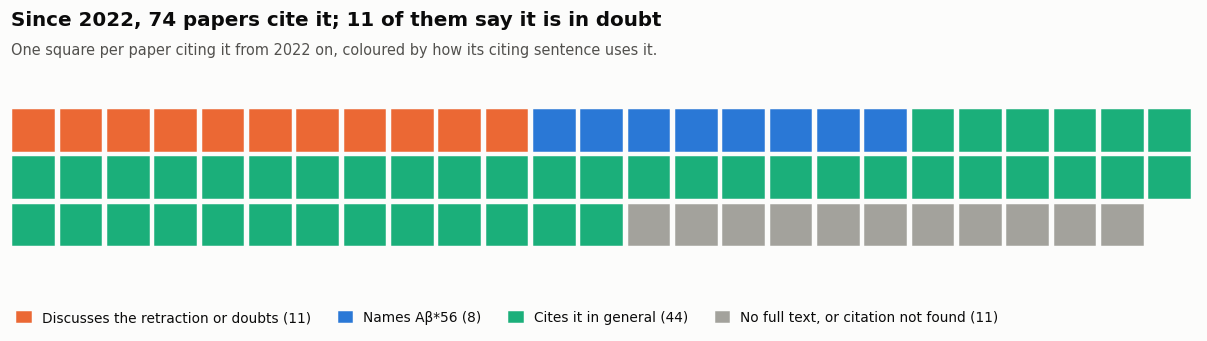

In [11]:
since = int((DOUBTS_PUBLIC or RETRACTED or str(last_year))[:4])
late = cited_by[cited_by["year"] >= since].sort_values("year", ascending=False)
doubting = (late["kind"] == KINDS[0]).sum()
charts.waffle(list(late.sort_values("year")["kind"]), KINDS, COLOURS,
              f"Since {since}, {len(late)} papers cite it; {doubting} of them say it is in doubt",
              f"One square per paper citing it from {since} on, coloured by how its citing sentence uses it.")

### Every citation since the retraction

The papers citing it from the year of the retraction to today, newest first, with the sentence in which each one cites it. Click a title to open it in PubMed. The year is the year of publication, so papers from the retraction year may have been written before it; and PubMed adds recent papers with a delay of weeks to months.

In [12]:
recent_from = int(RETRACTED[:4]) if RETRACTED else last_year - 2
recent = cited_by[cited_by["year"] >= recent_from].sort_values(["year", "pmid"], ascending=False)
verbs = dict(zip(KINDS, ["discussing the retraction or doubts", f"naming {FINDING}", "citing it in general", "not read"]))
counts = recent["kind"].value_counts().reindex(KINDS, fill_value=0)
print(f"{len(recent)} papers cite it from {recent_from} to {last_year}:",
      ", ".join(f"{n} {verbs[k]}" for k, n in counts.items() if n))
charts.paper_table(recent.to_dict("records"), COLOURS)

24 papers cite it from 2024 to 2026: 7 discussing the retraction or doubts, 1 naming Aβ*56, 11 citing it in general, 5 not read


Year,Paper,How it cites it,The sentence that cites it
2026,Targeting soluble misfolded oligomers in anti-amyloid research.Nature reviews. Chemistry · PMID 42624989,"No full text, or citation not found",not read
2026,Performance of AI Tools in Citing Retracted Literature : Content Analysis.Journal of medical Internet research · PMID 42066286,"No full text, or citation not found",not read
2025,Unraveling the neuroprotective mechanisms of elephant black garlic extract against beta amyloid peptide-induced neurotoxicity.Frontiers in nutrition · PMID 41624198,Cites it in general,"The amyloid-beta (Aβ) hypothesis proposes that soluble Aβ oligomers (SO-Aβ) are major drivers of synaptic dysfunction and neuronal injury ([this paper], 3)."
2025,"Alzheimer Syndrome or Age-Related Dementia-History, Therapy and Prevention.Journal of clinical medicine · PMID 41227148",Discusses the retraction or doubts,"Chistian Piller, journalist at e-Science, documented several examples of this scientific pressure: the retraction of an influential article published in 2006 in Nature [[this paper],96] about the role of the βA oligomer Ab*56, that altered memory [97]; the resignation of the NIA Neuroscience Director, for suspicion of scientific misconduct [39,98]; the withdrawal of the drug simufilan for fraud in a trial [99]."
2025,"""Non-Markovian"" and ""directional"" errors inhibit scientific self-correction and can lead fields of study astray: an illustration using gardening and obesity-related outcomes.BMC medical research methodology · PMID 40413393",Discusses the retraction or doubts,"In an extreme example, post-publication peer review and “sleuthing” successfully identified serious errors in Alzheimer’s disease research [[this paper], 6], but more than a decade after the original publication, by which time substantial costs of multiple types were incurred."
2025,"APOE deficiency inhibits amyloid-facilitated (A) tau pathology (T) and neurodegeneration (N), halting progressive ATN pathology in a preclinical model.Molecular psychiatry · PMID 40307424",Cites it in general,"The underlying molecular and cellular mechanisms of progression beyond amyloid pathology, as well as the toxic Aβ and tau culprits [[this paper]–27], remain to be unequivocally defined, which is required to design therapeutic strategies that halt ATN progression and effectively impact AD symptom progression."
2025,Cellular Prion Protein and Amyloid-β Oligomers in Alzheimer's Disease-Are There Connections?International journal of molecular sciences · PMID 40076721,Cites it in general,"Their ability to inhibit long-term potentiation (LTP) and many other critical neuronal activities is responsible for the classic model of synaptic plasticity and memory loss in vivo, for example, in middle-aged Tg2576 mice, which are equipped with a variant of human amyloid-β precursor protein (APP) associated with AD and in culture cells [9,[this paper],11,12]."
2025,"Presenilin, γ-Secretase, and the Search for Pathogenic Triggers of Alzheimer's Disease.Biochemistry · PMID 39996369",Discusses the retraction or doubts,"Candidates have included dimers,51 dodecamers52 (note: the initial 2006 study identifying dodecamers[this paper] was recently retracted due to data manipulation), and even a heterogeneous “oligomeric soup”.54, 55"
2025,Recent Advances in Co-Condensation and Co-Aggregation of Amyloid Proteins Linked to Neurodegenerative Diseases.Current protein & peptide science · PMID 39950286,"No full text, or citation not found",not read
2025,Morphological and Molecular Profiling of Amyloid-β Species in Alzheimer's Pathogenesis.Molecular neurobiology · PMID 39446217,"No full text, or citation not found",not read


## 6. Retracted papers that cite it

Retractions cluster: when one paper falls, papers by the same authors, or built on the same data, are often examined too. PubMed flags each citing paper that has itself been retracted. The last column lists the authors it shares with the retracted paper, matched by last name and first initial.

In [13]:
retracted = cited_by[cited_by["retracted"]].copy()
retracted["their_citers"] = retracted["pmid"].map(lambda p: len(citers.get(p, [])))
retracted[["year", "pmid", "title", "kind", "their_citers", "shared_authors"]].sort_values("year")

,year,pmid,title,kind,their_citers,shared_authors
915,2010,20655472,SIRT1 suppresses beta-amyloid production by activating the alpha-secretase gene ADAM10.,Cites it in general,209,
981,2011,20031278,Cognitive effects of cell-derived and synthetically derived Aβ oligomers.,Names Aβ*56,71,"Lesné Sylvain, Ashe Karen H"
682,2012,22836259,Soluble α-synuclein is a novel modulator of Alzheimer's disease pathophysiology.,"No full text, or citation not found",79,Lesné Sylvain E
651,2012,23175838,The complex PrP(c)-Fyn couples human oligomeric Aβ with pathological tau changes in Alzheimer's disease.,"No full text, or citation not found",174,Lesné Sylvain E
316,2017,28487416,The amyloid-β oligomer Aβ*56 induces specific alterations in neuronal signaling that lead to tau phosphorylation and aggregation.,Names Aβ*56,60,Lesné Sylvain E
163,2020,32246090,In situ structural characterization of early amyloid aggregates in Alzheimer's disease transgenic mice and Octodon degus.,Names Aβ*56,3,


## 7. Where did its influence travel?

Some citing papers carried the paper much further than others: a widely cited review reaches thousands of readers. The first chart ranks the citing papers by how many papers cite **them**.

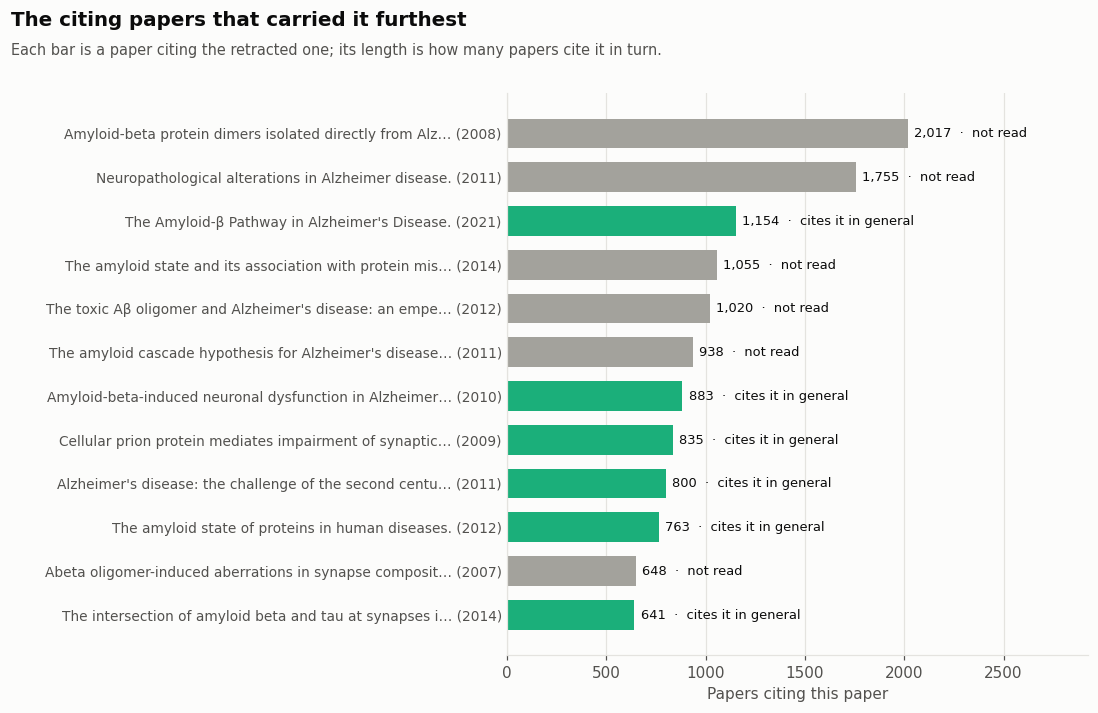

In [14]:
cited_by["their_citers"] = cited_by["pmid"].map(lambda p: len(citers.get(p, [])))
top = cited_by.nlargest(12, "their_citers")
charts.carriers([f"{tu.short(t, 55)} ({y})" for t, y in zip(top["title"], top["year"])], list(top["their_citers"]),
                list(top["kind"]), COLOURS, "The citing papers that carried it furthest")

The second chart follows every second-step paper back to the paper it cites. Each one is counted once, by its most specific link: a paper citing both a paper that names Aβ\*56 and a review that cites it in general counts as building on Aβ\*56.

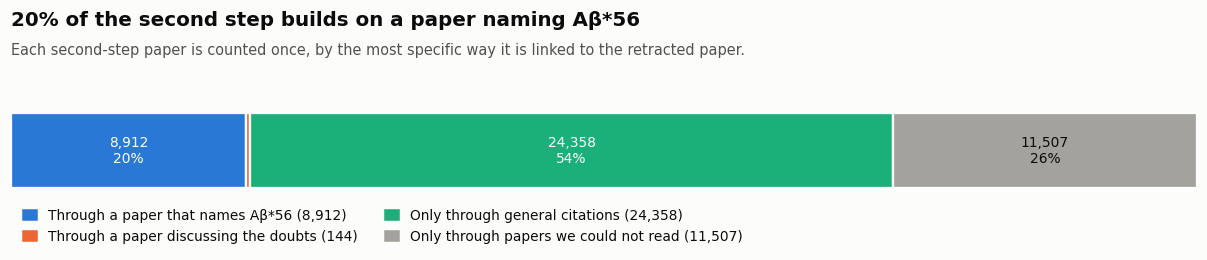

In [15]:
via = {}
for kind in [KINDS[1], KINDS[0], KINDS[2], KINDS[3]]:   # most specific first
    for pmid in cited_by.loc[cited_by["kind"] == kind, "pmid"]:
        for q in citers.get(pmid, []):
            if q in hop2:
                via.setdefault(q, kind)
labels = {KINDS[1]: f"Through a paper that names {FINDING}", KINDS[0]: "Through a paper discussing the doubts",
          KINDS[2]: "Only through general citations", KINDS[3]: "Only through papers we could not read"}
parts = [(labels[k], sum(1 for v in via.values() if v == k), COLOURS[k]) for k in [KINDS[1], KINDS[0], KINDS[2], KINDS[3]]]
charts.composition(parts, len(hop2), f"{parts[0][1] / len(hop2):.0%} of the second step builds on a paper naming {FINDING}",
                   "Each second-step paper is counted once, by the most specific way it is linked to the retracted paper.")

## 8. Compared with its neighbors

Is that much reach unusual? The papers PubMed finds most **similar** to the retracted one are a fair comparison: same topic, similar methods.

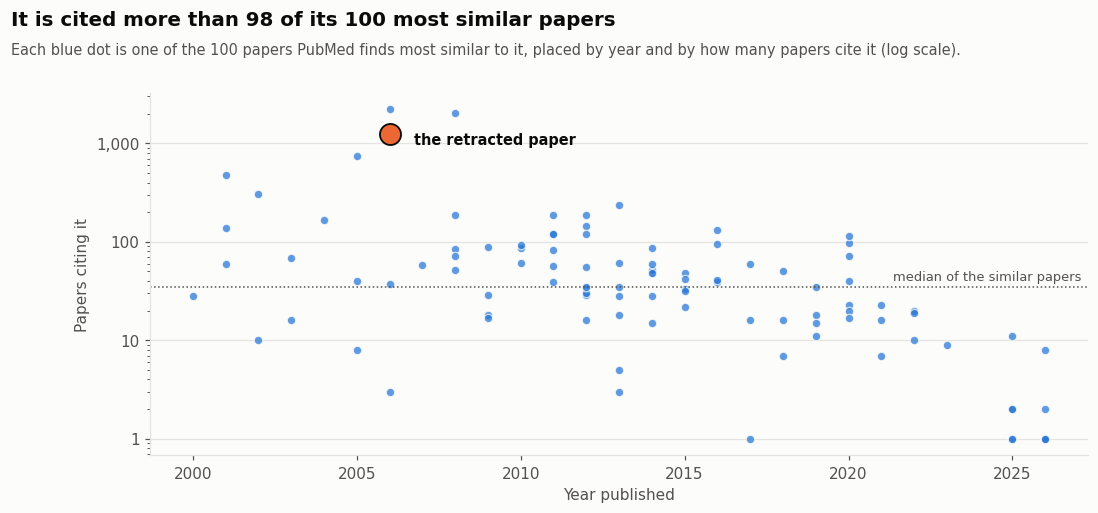

In [16]:
similar_citers = ci.citers_of([a.pmid for a in hood.similar])
similar = pd.DataFrame([{"year": int(a.year), "citations": len(similar_citers.get(a.pmid, []))}
                        for a in hood.similar if a.year and a.year.isdigit()])
beaten = (similar["citations"] < len(hop1)).sum()
charts.compared(list(similar["year"]), list(similar["citations"]), first_year, len(hop1), "the retracted paper",
                f"It is cited more than {beaten} of its {len(similar)} most similar papers")

## 9. A knowledge graph of the paper's impact

Everything above becomes an Obsidian knowledge graph in two steps:

1. The retracted paper's neighborhood: every paper citing it and the 100 most similar papers, each a note with its MeSH topics and flags.
2. The neighborhoods of some citing papers, their **neighbors' neighbors**: the retracted citing papers, then the most-cited papers that name Aβ\*56, up to `SECOND_HOP_SEEDS`, with 30 similar, citing and cited papers each.

Then each citing paper's note gets four properties of its own: `hop`, `citation_kind`, `citation_sentence`, the sentence that cites the paper, and `citation_source`, where that sentence was read. Obsidian shows them on each note, and a table, **Citation impact.base**, lists the citing papers by kind. Rebuilding the graph keeps them.

In [17]:
TOPIC = "abeta56 retraction impact"
with tu.quiet():
    result = create_kg(TOPIC, seeds=[SEED], max_per_relation=5000)
    named = cited_by[cited_by["kind"] == f"Names {FINDING}"].nlargest(SECOND_HOP_SEEDS, "their_citers")
    second_seeds = list(dict.fromkeys(list(retracted["pmid"]) + list(named["pmid"])))[:SECOND_HOP_SEEDS]
    result = create_kg(TOPIC, seeds=second_seeds, max_per_relation=30)
print(result)

properties = {SEED: {"hop": 0}}
for row in cited_by.itertuples():
    sentence = row.sentence.replace(ci.CITE, f"[PMID {SEED}]")
    properties[row.pmid] = {"hop": 1, "citation_kind": row.kind, "citation_sentence": tu.short(sentence, 400),
                            "citation_source": row.source}
for pmid in hop2:
    properties.setdefault(pmid, {"hop": 2})
print("Notes annotated:", ci.annotate(result.kg_dir, properties))
print("Table:", ci.write_base(result.kg_dir).name)


Knowledge graph: abeta56 retraction impact
Folder:            workspace\retraction_impact\kg_abeta56_retraction_impact
Study searches:    0 (0 run now, 0 new articles)
Study seeds:       11 (10 fetched now)
Obsidian vault
Vault:             workspace\retraction_impact\kg_abeta56_retraction_impact
Sources:           11
Papers:            2023 (0 full text, 2023 stubs)
MeSH concepts:     2426
Collections:       11
Notes:             1186 created, 983 updated, 2292 unchanged
PubMed records:    90 fetched
  - Without MeSH:  282 (offline, too new, or a journal outside MEDLINE)


Notes annotated: 1684
Table: Citation impact.base


A map of the graph: the papers citing the retracted one around it, grouped by kind, and the neighborhoods fetched in step 2 fanned out around their papers.

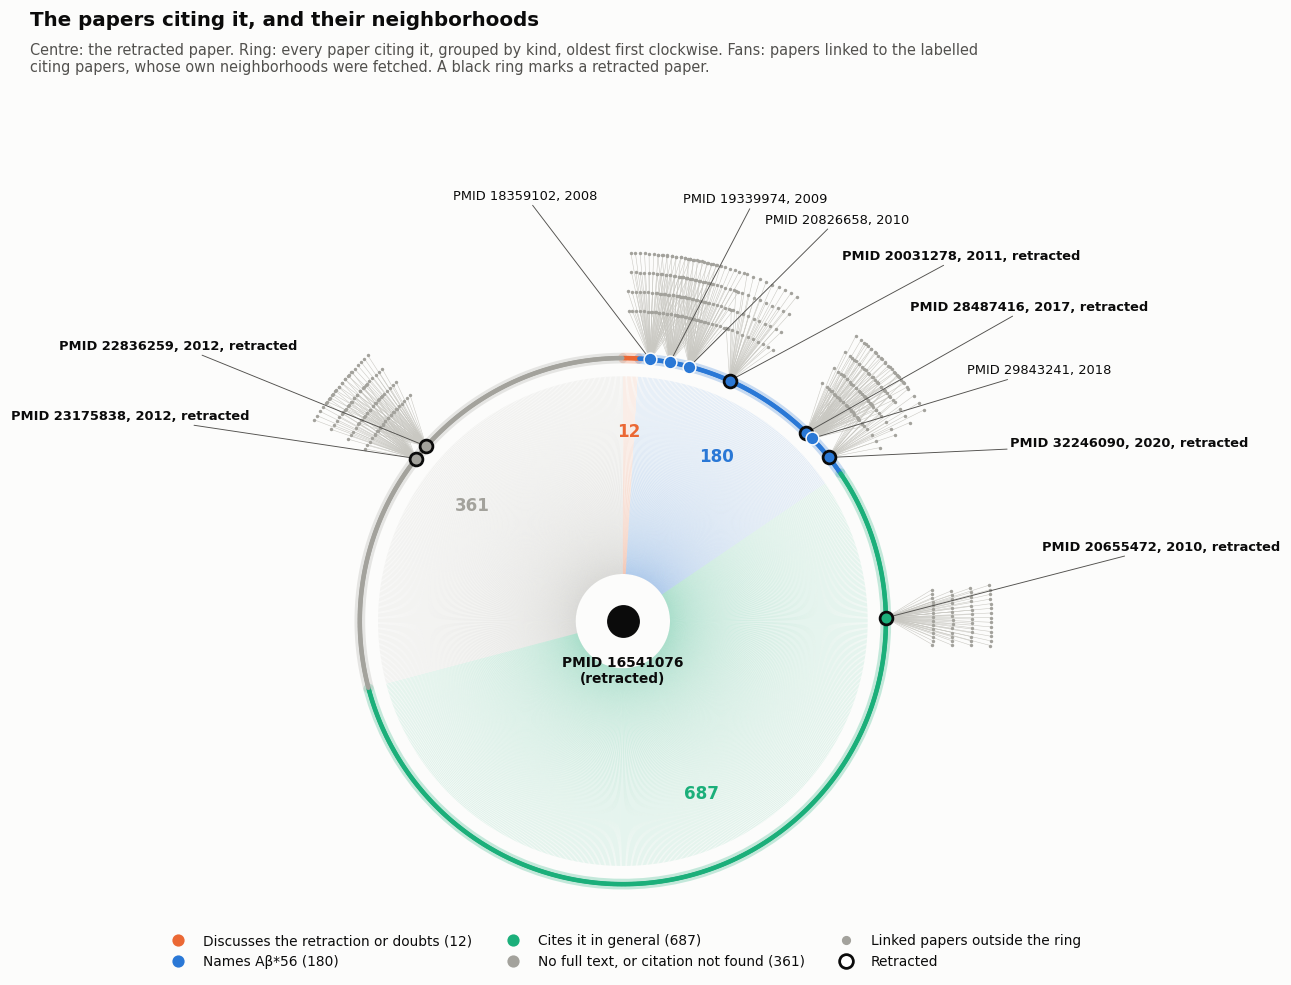

In [18]:
kg = tu.read_kg(result.kg_dir)
charts.radial_map(kg, SEED, dict(zip(cited_by["pmid"], cited_by["kind"])), KINDS, COLOURS, second_seeds,
                  "The papers citing it, and their neighborhoods")

**Open it in Obsidian.** Choose **Open folder as vault** and select the folder printed above, `kg_abeta56_retraction_impact`; the [Obsidian guide](guides/obsidian.md) explains the rest. Then:

- Open **Citation impact** for the table of citing papers, one view per kind: you can read every citing sentence there, sort by year, and add your own columns.
- Open the retracted paper's note, `PMID16541076`, to see every paper citing it, and its retraction flag.
- Search `[citation_kind: "Discusses the retraction or doubts"]` to find the papers that discuss the retraction.

![The Citation impact table in Obsidian, showing the papers that discuss the retraction, with the sentence in which each one cites it](guides/images/obsidian-citation-impact.png)

In Google Colab, the next cell saves the graph to your computer as a zip file. A copy of the graph from the saved run is also in the repository, in [`knowledge_graphs/kg_abeta56_retraction_impact`](knowledge_graphs/README.md): download it to explore the graph without running this notebook.

In [19]:
if tu.in_colab():
    tu.download(result.kg_dir)

## 10. At a glance

The headline numbers of this run, for a slide or a report.

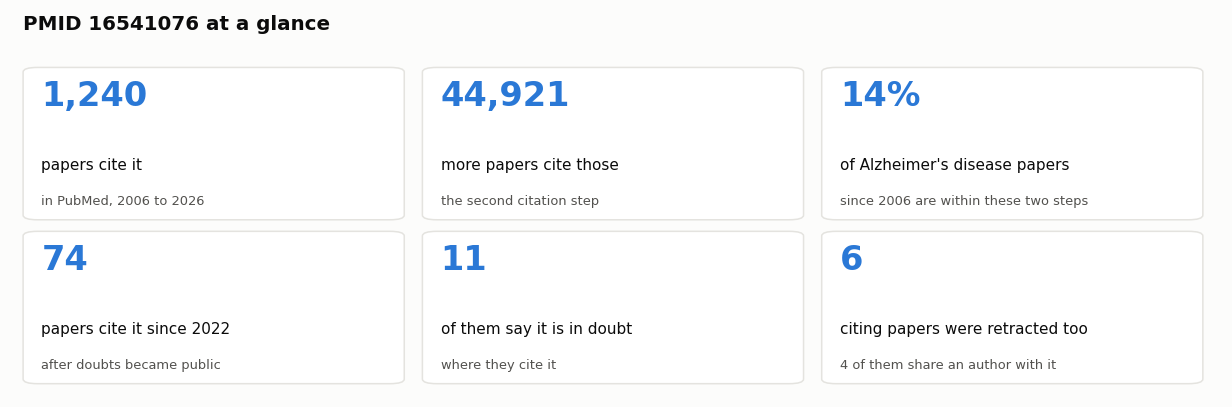

In [20]:
late_since = f"since {since}"
charts.key_numbers([
    (f"{len(hop1):,}", "papers cite it", f"in PubMed, {first_year} to {last_year}"),
    (f"{len(hop2):,}", "more papers cite those", "the second citation step"),
    (f"{field_near / field_total:.0%}", f"of {field_label} papers", f"since {first_year} are within these two steps"),
    (f"{len(late)}", f"papers cite it {late_since}", "after doubts became public" if DOUBTS_PUBLIC else "recently"),
    (f"{doubting}", "of them say it is in doubt", "where they cite it"),
    (f"{len(retracted)}", "citing papers were retracted too",
     f"{(retracted['shared_authors'] != '').sum()} of them share an author with it"),
], f"PMID {SEED} at a glance")

## 11. What these numbers can and cannot tell you

- **The counts are PubMed's.** PubMed links a citation only when the citing article's full text is in PubMed Central, so it counts fewer citations than Google Scholar or Web of Science: 1,240 here, where nearly 2,500 have been reported for this paper. The shares and trends are more reliable than the totals.
- **The second step is an upper bound.** A paper two steps away may share nothing with Aβ\*56 beyond a common review. Section 7 shows how much of the reach passes through papers that name the finding.
- **The classification is by keywords.** "Controversy" may refer to the amyloid hypothesis in general rather than this paper, and a paper can discuss Aβ\*56 without the words in `FINDING_WORDS`. Read the sentences, in section 4 or in Obsidian, and the citations worth a second look, before you report a number.
- **Some sentences come from Semantic Scholar.** For papers whose full text is not in PubMed Central, the citing sentences are Semantic Scholar's, which are often shorter: on the papers both sources cover, they agree on the kind of citation nine times in ten, and where they differ, the full text found Aβ\*56 and Semantic Scholar's excerpt did not. Without an API key, Semantic Scholar answers slowly and sometimes not at all; the notebook then reads full text only.
- **A citation is not an endorsement.** Papers cite work to build on it, to compare with it, or to dispute it, and only the sentence tells which.
- **Retractions take time to spread.** PubMed marks the retracted paper, but citing papers written before the retraction stay as they are, and reviews keep their claims until they are revised.

To study another paper, change the settings at the top and run the notebook again. For a paper that has not been retracted, the same sections measure how its finding spread, and whether anyone has questioned it.

This question continues as a study in [`studies/abeta56_retraction_impact`](../studies/abeta56_retraction_impact/): the citing papers of this run frozen as a table, the second step fetched, a sourced account of what the paper claimed and what was wrong, counts of the claim and its correction in language-model training corpora, and probes of what models say about Aβ\*56.

**Next:** [tutorial 4](04_evidence_neighborhood.ipynb) explains evidence neighborhoods, and [tutorial 5](05_knowledge_graph.ipynb) the knowledge graph, in more depth.